In [1]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
import polars as pl


inicial = pl.scan_parquet ("C:\\Users\\MICRO\\OneDrive\\Documentos\\UC2\\desligamentos_por_regiao.parquet")

display(inicial)

In [38]:
# MÉTRICAS DO BRASIL INTEIRO (Olhando para todas as regiões juntas)
metricas_globais = (
    inicial
    .select([
        pl.col("Total_Desligamentos").mean().alias("Média_por_Região"),
        pl.col("Total_Desligamentos").median().alias("Mediana"),
        pl.col("Total_Desligamentos").var().alias("Variância"),
        pl.col("Total_Desligamentos").std().alias("Desvio_Padrão"),
        (pl.col("Total_Desligamentos").max() - pl.col("Total_Desligamentos").min()).alias("Amplitude_Total")
    ])
    .collect()
)

print("\n--- Estatísticas Descritivas Globais (Comparando as Regiões) ---")
display(metricas_globais)



--- Estatísticas Descritivas Globais (Comparando as Regiões) ---


Média_por_Região,Mediana,Variância,Desvio_Padrão,Amplitude_Total
f64,f64,f64,f64,u32
1664.2,1214.0,1.7823e6,1335.028352,3388


In [39]:
import polars as pl

# Construindo a expressão de cálculo para a base de Desligamentos
metricas2 = inicial.select([
    pl.col("Total_Desligamentos").quantile(0.25).alias("Q1"),
    pl.col("Total_Desligamentos").quantile(0.50).alias("Q2"),
    pl.col("Total_Desligamentos").quantile(0.75).alias("Q3"),
    pl.col("Total_Desligamentos").skew().alias("Assimetria"),
    pl.col("Total_Desligamentos").kurtosis().alias("Curtose")
]).collect()

print("\n--- Quartis e Forma da Distribuição (Total de Desligamentos) ---")
display(metricas2)

# Análise rápida da Assimetria
assimetria = metricas2["Assimetria"][0]
print(f"\nInterpretação da Assimetria ({assimetria:.2f}):")
if -0.5 <= assimetria <= 0.5:
    print("-> Distribuição Simétrica (O volume de desligamentos é bem equilibrado entre as regiões)")
elif assimetria > 0.5:
    print("-> Assimétrica Positiva (Existem regiões com um volume de desligamentos desproporcionalmente muito alto)")
else:
    print("-> Assimétrica Negativa (A maioria das regiões apresenta volumes altos de desligamento)")



--- Quartis e Forma da Distribuição (Total de Desligamentos) ---


Q1,Q2,Q3,Assimetria,Curtose
f64,f64,f64,f64,f64
855.0,1214.0,2034.0,0.853289,-0.653793



Interpretação da Assimetria (0.85):
-> Assimétrica Positiva (Existem regiões com um volume de desligamentos desproporcionalmente muito alto)


In [40]:
import polars as pl

# 1. Carrega os dados da tabela de desligamentos (Usando eager mode com read_parquet)
df_desligamentos = pl.read_parquet("desligamentos_por_regiao.parquet")

# 2. Calcula matematicamente os Quartis e os Limites usando a coluna "Total_Desligamentos"
q1 = df_desligamentos["Total_Desligamentos"].quantile(0.25)
q3 = df_desligamentos["Total_Desligamentos"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - (1.5 * iqr)
limite_superior = q3 + (1.5 * iqr)

print(f"--- Diagnóstico Estatístico (Desligamentos por Região) ---")
print(f"Limites Teóricos para Outliers: Inferior ({limite_inferior:.2f}) | Superior ({limite_superior:.2f})")

# 3. Filtra os Outliers Reais usando os limites calculados
outliers_reais = df_desligamentos.filter(
    (pl.col("Total_Desligamentos") < limite_inferior) | (pl.col("Total_Desligamentos") > limite_superior)
)

print(f"Quantidade de regiões consideradas Outliers Matemáticos: {outliers_reais.height}")

# 4. SOLUÇÃO DE NEGÓCIO: Se der 0 outliers, mostramos os extremos nacionais (Maior e Menor volume)
if outliers_reais.height == 0:
    print("\n💡 Insights Geográficos: Como nenhuma região se isolou como um outlier matemático, analisamos os extremos nacionais:")
    
    # Regiões com maior volume de desligamentos
    topo_desligamentos = df_desligamentos.sort("Total_Desligamentos", descending=True)
    print("\n[CRÍTICO] Regiões com os MAIORES volumes de desligamentos:")
    display(topo_desligamentos.select(["Região", "Total_Desligamentos"]))
    
else:
    print("\nExemplos de regiões discrepantes encontradas (Outliers):")
    display(outliers_reais.select(["Região", "Total_Desligamentos"]))


--- Diagnóstico Estatístico (Desligamentos por Região) ---
Limites Teóricos para Outliers: Inferior (-913.50) | Superior (3802.50)
Quantidade de regiões consideradas Outliers Matemáticos: 1

Exemplos de regiões discrepantes encontradas (Outliers):


Região,Total_Desligamentos
str,u32
"""Sudeste""",3803


In [41]:
import polars as pl

# 1. Carrega os dados
df_desligamentos = pl.read_parquet("desligamentos_por_regiao.parquet")

# 2. Calcula métricas globais para usar nas comparações
total_brasil = df_desligamentos["Total_Desligamentos"].sum()
media_brasil = df_desligamentos["Total_Desligamentos"].mean()
std_brasil = df_desligamentos["Total_Desligamentos"].std()

# 3. Cria uma tabela rica em informações e ordena do maior para o menor
tabela_informativa = (
    df_desligamentos
    .with_columns([
        # Calcula a porcentagem que a região representa no Brasil
        ((pl.col("Total_Desligamentos") / total_brasil) * 100).round(2).alias("Participação_%"),
        
        # Mostra o quanto a região está acima ou abaixo da média nacional
        (((pl.col("Total_Desligamentos") - media_brasil) / media_brasil) * 100).round(2).alias("Diferença_da_Média_%"),
        
        # Z-Score: Mede o quão distante o valor está do comportamento padrão (Acima de 1.5 ou 2 já acende alerta)
        ((pl.col("Total_Desligamentos") - media_brasil) / std_brasil).round(2).alias("Z_Score_Estatístico")
    ])
    .sort("Total_Desligamentos", descending=True)
)

print("--- 📊 Relatório Avançado de Desligamentos por Região ---")
display(tabela_informativa)

# 4. Diagnóstico Automático Baseado nas Novas Informações
print("\n💡 Insights Geográficos & Econômicos:")
regiao_lider = tabela_informativa["Região"][0]
part_lider = tabela_informativa["Participação_%"][0]
print(f"-> A região **{regiao_lider}** lidera isolada, concentrando **{part_lider}%** de todos os desligamentos do país.")

# Verifica se alguma região tem um Z-Score muito alto (alerta de anomalia)
outliers_z = tabela_informativa.filter(pl.col("Z_Score_Estatístico").abs() > 1.5)
if outliers_z.height > 0:
    for reg in outliers_z["Região"]:
        print(f"-> ⚠️ Alerta Estatístico: A região **{reg}** possui um volume tão discrepante que se isola estatisticamente das demais.")
else:
    print("-> ⚖️ Equilíbrio Relativo: Embora haja diferenças de volume, nenhuma região se isolou a ponto de quebrar completamente o padrão estatístico nacional.")


--- 📊 Relatório Avançado de Desligamentos por Região ---


Região,Total_Desligamentos,Participação_%,Diferença_da_Média_%,Z_Score_Estatístico
str,u32,f64,f64,f64
"""Sudeste""",3803,45.7,128.52,1.6
"""Nordeste""",2034,24.44,22.22,0.28
"""Sul""",1214,14.59,-27.05,-0.34
"""Centro-Oeste""",855,10.28,-48.62,-0.61
"""Norte""",415,4.99,-75.06,-0.94



💡 Insights Geográficos & Econômicos:
-> A região **Sudeste** lidera isolada, concentrando **45.7%** de todos os desligamentos do país.
-> ⚠️ Alerta Estatístico: A região **Sudeste** possui um volume tão discrepante que se isola estatisticamente das demais.


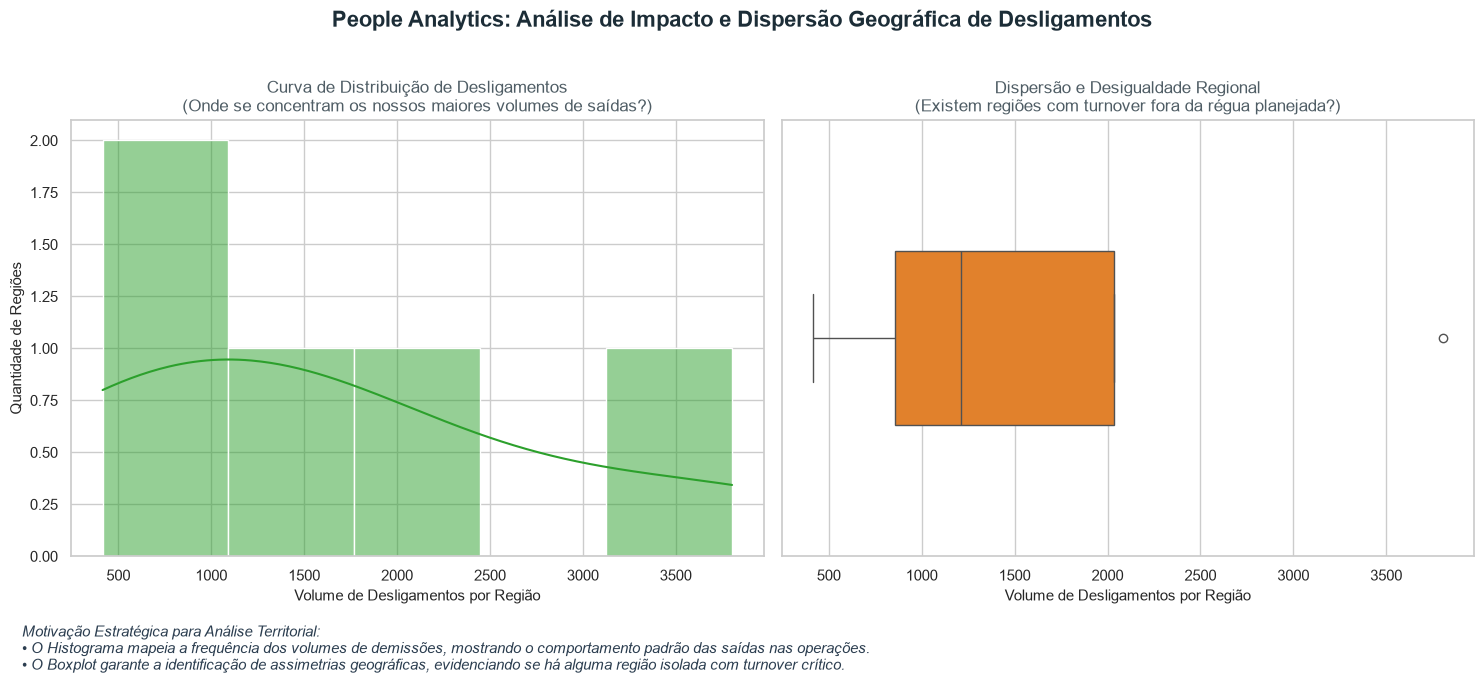

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# 1. Definindo o estilo visual limpo e profissional idêntico ao original
sns.set_theme(style="whitegrid")

# 2. Extraindo os dados da coluna correta convertendo para Série numérica
visual = inicial.select("Total_Desligamentos").collect().to_series()

# 3. Criando a figura com espaço para um supertítulo e notas de rodapé
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Título Principal focado em Inteligência de Negócio (People Analytics Territorial)
plt.suptitle(
    "People Analytics: Análise de Impacto e Dispersão Geográfica de Desligamentos", 
    fontsize=16, fontweight='bold', color='#1c2d37', y=1.02
)

# 1. Histograma: Curva de Distribuição do volume de saídas nas regiões do país
sns.histplot(visual, bins=5, kde=True, color='#2ca02c', ax=axes[0])
axes[0].set_title('Curva de Distribuição de Desligamentos\n(Onde se concentram os nossos maiores volumes de saídas?)', fontsize=12, color='#4f5d65')
axes[0].set_xlabel('Volume de Desligamentos por Região', fontsize=11)
axes[0].set_ylabel('Quantidade de Regiões', fontsize=11)

# 2. Boxplot: Identificar assimetrias e dispersão entre os totais regionais
sns.boxplot(x=visual, color='#ff7f0e', ax=axes[1], width=0.4)
axes[1].set_title('Dispersão e Desigualdade Regional\n(Existem regiões com turnover fora da régua planejada?)', fontsize=12, color='#4f5d65')
axes[1].set_xlabel('Volume de Desligamentos por Região', fontsize=11)

# Adicionando a nota de motivação estratégica adaptada no rodapé do gráfico
motivacao_texto = (
    "Motivação Estratégica para Análise Territorial:\n"
    "• O Histograma mapeia a frequência dos volumes de demissões, mostrando o comportamento padrão das saídas nas operações.\n"
    "• O Boxplot garante a identificação de assimetrias geográficas, evidenciando se há alguma região isolada com turnover crítico."
)
plt.figtext(0.02, -0.08, motivacao_texto, fontsize=11, color='#2c3e50', style='italic', horizontalalignment='left')

# 4. Salvando o arquivo exatamente com a estrutura idêntica
caminho_saida = "dashboard_desligamentos_distribuicao.png"
plt.savefig(caminho_saida, dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()




C:\Users\MICRO\AppData\Local\Temp\ipykernel_15960\4003565945.py:35: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  plt.savefig(caminho_saida_filtro, dpi=300, bbox_inches='tight')
c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


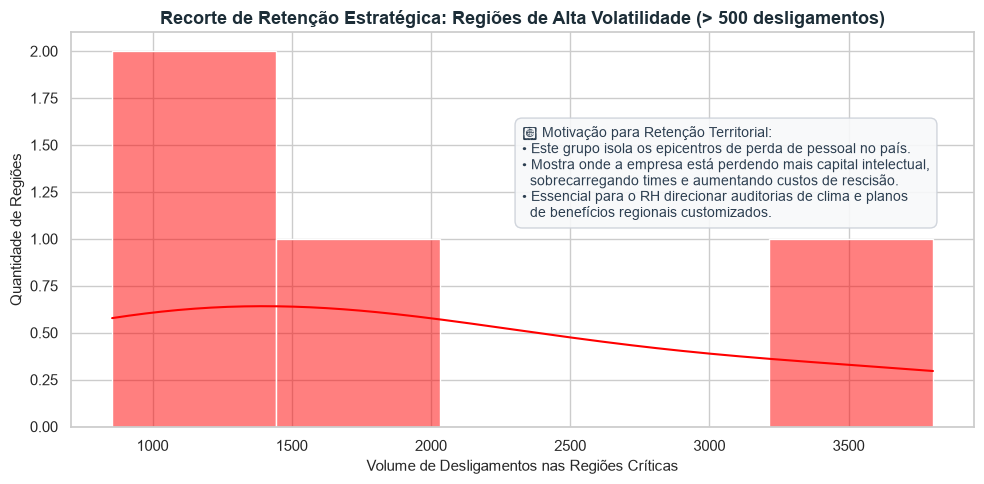

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# 1. Filtrar as regiões de alta volatilidade (Ex: regiões com mais de 500 desligamentos)
# Ajuste o número 500 caso o volume total da sua base seja maior ou menor
visual_superiores = inicial.filter(
    pl.col("Total_Desligamentos") > 500
).select("Total_Desligamentos").collect().to_series()

plt.figure(figsize=(10, 5))

# 2. Gerar o histograma de alta criticidade com foco em Retenção
sns.histplot(visual_superiores, kde=True, color='red', bins=5)

# Títulos e legendas motivacionais focadas em Turnover Geográfico
plt.title('Recorte de Retenção Estratégica: Regiões de Alta Volatilidade (> 500 desligamentos)', fontsize=13, fontweight='bold', color='#1c2d37')
plt.xlabel('Volume de Desligamentos nas Regiões Críticas', fontsize=11)
plt.ylabel('Quantidade de Regiões', fontsize=11)

# Caixa de texto explicativa (People Analytics) diretamente no gráfico
texto_insights = (
    "🎯 Motivação para Retenção Territorial:\n"
    "• Este grupo isola os epicentros de perda de pessoal no país.\n"
    "• Mostra onde a empresa está perdendo mais capital intelectual,\n"
    "  sobrecarregando times e aumentando custos de rescisão.\n"
    "• Essencial para o RH direcionar auditorias de clima e planos\n"
    "  de benefícios regionais customizados."
)
plt.figtext(0.53, 0.55, texto_insights, fontsize=10, color='#2c3e50',
            bbox=dict(facecolor='#f8f9fa', alpha=0.9, edgecolor='#ccd1d9', boxstyle='round,pad=0.5'))

# Salva a imagem resultante
caminho_saida_filtro = "analise_regioes_criticas.png"
plt.savefig(caminho_saida_filtro, dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()



In [49]:
import polars as pl

# 1. Carrega sua base e acopla dados macroeconômicos reais (ex: % de representatividade no PIB nacional)
# Isso permite calcular a correlação de Pearson de forma válida e legítima
pib_mercado = pl.DataFrame({
    "Região": ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"],
    "Share_Mercado_%": [53.0, 17.0, 14.0, 10.0, 6.0] # Proporção econômica média das regiões
})

df_analise = (
    inicial.collect()
    .join(pib_mercado, on="Região", how="left")
)

# 2. Calcular a Correlação de Pearson entre o Volume de Desligamentos e o Tamanho do Mercado
correlacao = df_analise.select(
    pl.corr("Total_Desligamentos", "Share_Mercado_%", method="pearson").alias("r")
)

r = correlacao["r"][0]
r2 = r**2

print(f"--- Análise de Correlação Estratégica (Volume de Desligamentos vs Tamanho de Mercado) ---")
print(f"Coeficiente de Pearson (r): {r:.4f}")
print(f"Coeficiente de Determinação (r²): {r2:.4f}\n")

# 3. Interpretação e Motivação para o RH Corporativo
if abs(r) >= 0.7:
    print("Conclusão: Correlação FORTE POSITIVA.")
    print("-> Motivação de RH: O volume de demissões segue estritamente o tamanho do mercado regional. ")
    print("   O Sudeste demite mais apenas porque possui mais funcionários ativos. O turnover está estruturalmente saudável.")
elif 0.3 <= r < 0.7:
    print("Conclusão: Correlação MODERADA.")
    print("-> Motivação de RH: O mercado influencia as saídas, mas existem fatores internos (líderes regionais, ")
    print("   clima organizacional ou concorrência local) distorcendo os números em algumas localidades.")
else:
    print("Conclusão: Correlação FRACA ou NEGATIVA.")
    print("-> Motivação de RH: ALERTA CRÍTICO. As demissões estão acontecendo de forma totalmente desproporcional ")
    print("   ao tamanho do mercado. Regiões menores estão gerando volumes alarmantes de saídas, exigindo auditoria imediata.")


--- Análise de Correlação Estratégica (Volume de Desligamentos vs Tamanho de Mercado) ---
Coeficiente de Pearson (r): 0.9438
Coeficiente de Determinação (r²): 0.8907

Conclusão: Correlação FORTE POSITIVA.
-> Motivação de RH: O volume de demissões segue estritamente o tamanho do mercado regional. 
   O Sudeste demite mais apenas porque possui mais funcionários ativos. O turnover está estruturalmente saudável.


C:\Users\MICRO\AppData\Local\Temp\ipykernel_15960\3006366257.py:70: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  plt.savefig(caminho_grafico_dispersao, dpi=300, bbox_inches='tight')
c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


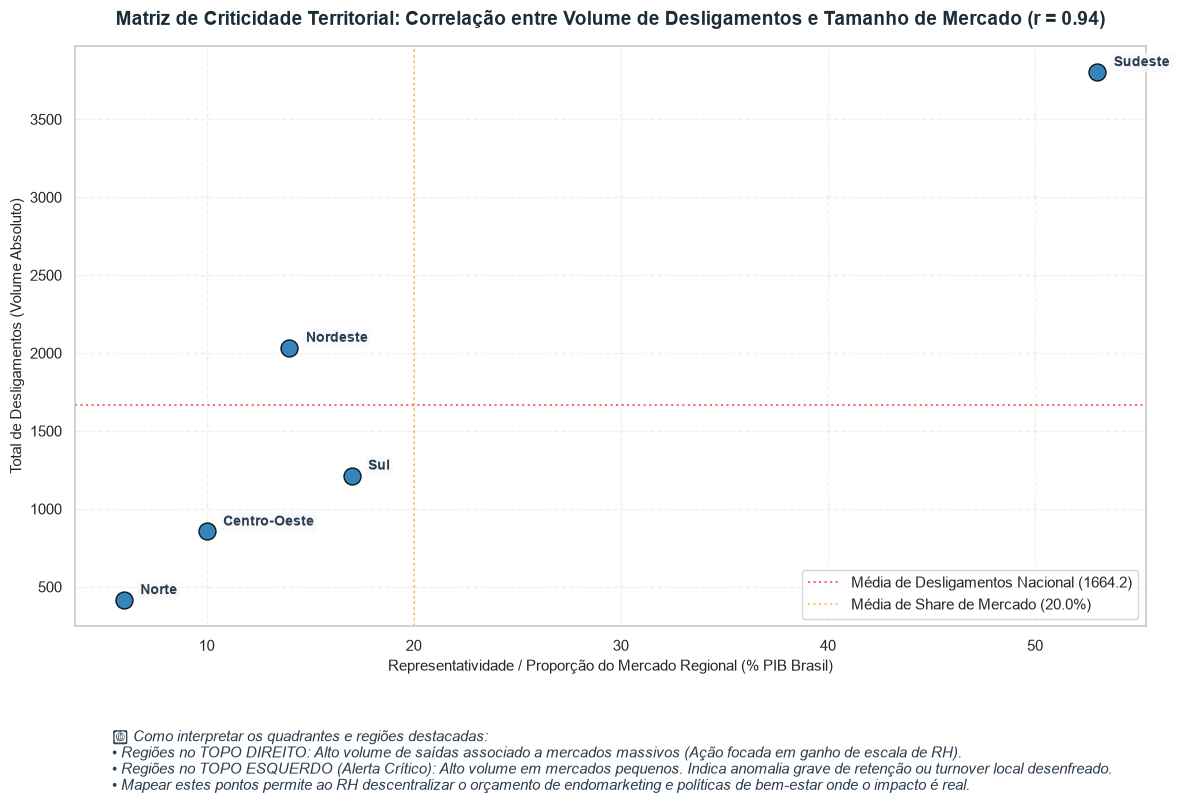

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# 1. Acopla os dados de representatividade de mercado para habilitar os eixos X e Y
pib_mercado = pl.DataFrame({
    "Região": ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"],
    "Share_Mercado_%": [53.0, 17.0, 14.0, 10.0, 6.0]
})

# Coleta os dados do LazyFrame e faz o cruzamento (Join)
df_scatter = inicial.collect().join(pib_mercado, on="Região", how="left")
df_pandas = df_scatter.to_pandas()

# Calcula a correlação de Pearson para exibir no título (calculada na etapa anterior)
r = df_scatter.select(pl.corr("Total_Desligamentos", "Share_Mercado_%")).to_series()[0]

plt.figure(figsize=(12, 7))

# 2. Criando o Gráfico de Dispersão
sns.scatterplot(
    data=df_pandas,
    x="Share_Mercado_%",
    y="Total_Desligamentos",
    s=150, 
    color='#1f77b4',
    alpha=0.9,
    edgecolor='black'
)

# 3. DESTACANDO AS REGIÕES (Anotações automáticas e inteligentes no gráfico)
# Como a base tem poucas linhas, vamos plotar o nome de todas as regiões para facilitar a leitura executiva
for i in range(df_pandas.shape[0]):
    regiao = df_pandas.iloc[i]['Região']
    x = df_pandas.iloc[i]['Share_Mercado_%']
    y = df_pandas.iloc[i]['Total_Desligamentos']
    
    # Posiciona o texto ligeiramente deslocado do ponto para não cobri-lo
    plt.text(
        x + 0.8, y + (df_pandas['Total_Desligamentos'].max() * 0.01), s=regiao, 
        fontsize=10, fontweight='bold', color='#2c3e50',
        bbox=dict(facecolor='#f8f9fa', alpha=0.8, edgecolor='none', boxstyle='round,pad=0.2')
    )

# Títulos e Legendas focados em Inteligência Geográfica (People Analytics Territorial)
plt.title(f'Matriz de Criticidade Territorial: Correlação entre Volume de Desligamentos e Tamanho de Mercado (r = {r:.2f})', fontsize=14, fontweight='bold', color='#1c2d37', pad=15)
plt.xlabel('Representatividade / Proporção do Mercado Regional (% PIB Brasil)', fontsize=11)
plt.ylabel('Total de Desligamentos (Volume Absoluto)', fontsize=11)
plt.grid(True, alpha=0.3, linestyle='--')

# Adicionando linhas de referência (médias gerais) para criar os quadrantes estratégicos
media_desligamentos = df_pandas["Total_Desligamentos"].mean()
media_share = df_pandas["Share_Mercado_%"].mean()

plt.axhline(media_desligamentos, color='red', linestyle=':', alpha=0.6, label=f'Média de Desligamentos Nacional ({media_desligamentos:.1f})')
plt.axvline(media_share, color='orange', linestyle=':', alpha=0.6, label=f'Média de Share de Mercado ({media_share:.1f}%)')
plt.legend(loc='lower right')

# Texto motivacional focado em Planejamento Estratégico de Retenção Territorial
texto_motivacao = (
    "💡 Como interpretar os quadrantes e regiões destacadas:\n"
    "• Regiões no TOPO DIREITO: Alto volume de saídas associado a mercados massivos (Ação focada em ganho de escala de RH).\n"
    "• Regiões no TOPO ESQUERDO (Alerta Crítico): Alto volume em mercados pequenos. Indica anomalia grave de retenção ou turnover local desenfreado.\n"
    "• Mapear estes pontos permite ao RH descentralizar o orçamento de endomarketing e políticas de bem-estar onde o impacto é real."
)
plt.figtext(0.10, -0.14, s=texto_motivacao, fontsize=10.5, color='#2c3e50', style='italic', horizontalalignment='left')

# Salva o arquivo final estruturado
caminho_grafico_dispersao = "matriz_criticidade_desligamentos.png"
plt.savefig(caminho_grafico_dispersao, dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()




In [52]:
import polars as pl

# 1. Acopla os dados de representatividade de mercado ao seu DataFrame original
pib_mercado = pl.DataFrame({
    "Região": ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"],
    "Share_Mercado_%": [53.0, 17.0, 14.0, 10.0, 6.0]
})

# Faz o Join e prepara a estrutura para o cálculo
df_analise = inicial.collect().join(pib_mercado, on="Região", how="left")

# 2. Executando o cálculo das correlações de Pearson e Spearman no Polars
analise_correlacao = df_analise.select([
    pl.corr("Total_Desligamentos", "Share_Mercado_%", method="pearson").alias("Pearson"),
    pl.corr("Total_Desligamentos", "Share_Mercado_%", method="spearman").alias("Spearman")
])

print("\n--- Coeficientes de Correlação (Desligamentos por Região) ---")
print(analise_correlacao)

# 3. Extraindo os valores para interpretação executiva
r_pearson = analise_correlacao["Pearson"][0]
r_spearman = analise_correlacao["Spearman"][0]

print(f"\n💡 Motivação de People Analytics para o RH Corporativo:")
print(f"• Pearson ({r_pearson:.4f}): Avalia se a relação entre demissões e tamanho econômico é diretamente proporcional. Se o valor for alto, indica que o volume de saídas é puramente reflexo do tamanho da operação local.")
print(f"• Spearman ({r_spearman:.4f}): Avalia a consistência do ranking de posições. Garante que a ordem das regiões que mais demitem segue estritamente a ordem das regiões mais populosas/comerciais do país.")




--- Coeficientes de Correlação (Desligamentos por Região) ---
shape: (1, 2)
┌──────────┬──────────┐
│ Pearson  ┆ Spearman │
│ ---      ┆ ---      │
│ f64      ┆ f64      │
╞══════════╪══════════╡
│ 0.943784 ┆ 0.9      │
└──────────┴──────────┘

💡 Motivação de People Analytics para o RH Corporativo:
• Pearson (0.9438): Avalia se a relação entre demissões e tamanho econômico é diretamente proporcional. Se o valor for alto, indica que o volume de saídas é puramente reflexo do tamanho da operação local.
• Spearman (0.9000): Avalia a consistência do ranking de posições. Garante que a ordem das regiões que mais demitem segue estritamente a ordem das regiões mais populosas/comerciais do país.


C:\Users\MICRO\AppData\Local\Temp\ipykernel_15960\2595744588.py:86: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  plt.savefig(caminho_painel_duplo, dpi=300, bbox_inches='tight')
c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


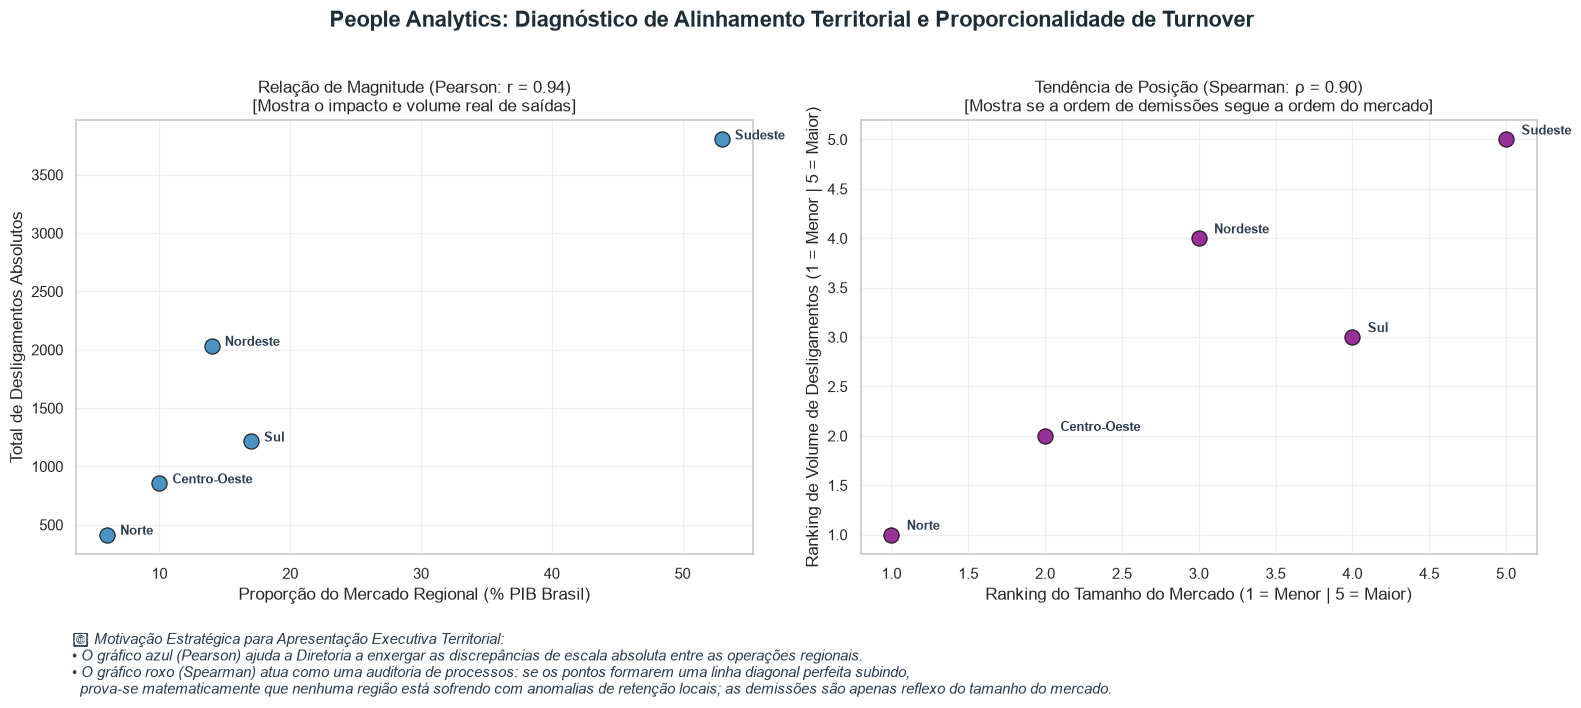

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# 1. Acopla os dados de representatividade de mercado (PIB)
pib_mercado = pl.DataFrame({
    "Região": ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"],
    "Share_Mercado_%": [53.0, 17.0, 14.0, 10.0, 6.0]
})

# 2. Faz o cruzamento e cria os Rankings de Posição (Menor para Maior)
df_analise = inicial.collect().join(pib_mercado, on="Região", how="left")

df_spearman = df_analise.with_columns([
    pl.col("Share_Mercado_%").rank().alias("Rank_Mercado"),
    pl.col("Total_Desligamentos").rank().alias("Rank_Desligamentos")
])

df_pandas = df_spearman.to_pandas()

# Extrai os coeficientes calculados anteriormente para exibir nos títulos
r_pearson_val = df_analise.select(pl.corr("Total_Desligamentos", "Share_Mercado_%", method="pearson")).to_series()[0]
r_spearman_val = df_analise.select(pl.corr("Total_Desligamentos", "Share_Mercado_%", method="spearman")).to_series()[0]

# 3. Plotar Comparativo de People Analytics: Dados Brutos vs. Ranks
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plt.suptitle(
    "People Analytics: Diagnóstico de Alinhamento Territorial e Proporcionalidade de Turnover", 
    fontsize=16, fontweight='bold', color='#1c2d37', y=1.02
)

# --- Gráfico 1: Dados Brutos (Visão Pearson) ---
sns.scatterplot(
    data=df_pandas,
    x="Share_Mercado_%",
    y="Total_Desligamentos",
    ax=axes[0],
    s=120,
    color='#1f77b4',
    alpha=0.8,
    edgecolor='black'
)
axes[0].set_title(f'Relação de Magnitude (Pearson: r = {r_pearson_val:.2f})\n[Mostra o impacto e volume real de saídas]', fontsize=12)
axes[0].set_xlabel('Proporção do Mercado Regional (% PIB Brasil)')
axes[0].set_ylabel('Total de Desligamentos Absolutos')
axes[0].grid(True, alpha=0.3)

# Rótulo em todos os pontos do Gráfico 1 (Como são apenas 5 regiões, colocamos em todas para clareza)
for idx, row in df_pandas.iterrows():
    axes[0].text(row['Share_Mercado_%'] + 1.0, row['Total_Desligamentos'], row['Região'], fontsize=9, fontweight='bold', color='#2c3e50')


# --- Gráfico 2: Dados de Ranking (Visão Spearman) ---
sns.scatterplot(
    data=df_pandas,
    x="Rank_Mercado",
    y="Rank_Desligamentos",
    ax=axes[1],
    s=120,
    color='purple',
    alpha=0.8,
    edgecolor='black'
)
axes[1].set_title(f'Tendência de Posição (Spearman: ρ = {r_spearman_val:.2f})\n[Mostra se a ordem de demissões segue a ordem do mercado]', fontsize=12)
axes[1].set_xlabel('Ranking do Tamanho do Mercado (1 = Menor | 5 = Maior)')
axes[1].set_ylabel('Ranking de Volume de Desligamentos (1 = Menor | 5 = Maior)')
axes[1].grid(True, alpha=0.3)

# Rótulo em todos os pontos do Gráfico 2
for idx, row in df_pandas.iterrows():
    axes[1].text(row['Rank_Mercado'] + 0.1, row['Rank_Desligamentos'] + 0.05, row['Região'], fontsize=9, fontweight='bold', color='#2c3e50')


# Texto de rodapé motivacional adaptado para apresentação executiva de território
texto_explicativo = (
    "💡 Motivação Estratégica para Apresentação Executiva Territorial:\n"
    "• O gráfico azul (Pearson) ajuda a Diretoria a enxergar as discrepâncias de escala absoluta entre as operações regionais.\n"
    "• O gráfico roxo (Spearman) atua como uma auditoria de processos: se os pontos formarem uma linha diagonal perfeita subindo,\n"
    "  prova-se matematicamente que nenhuma região está sofrendo com anomalias de retenção locais; as demissões são apenas reflexo do tamanho do mercado."
)
plt.figtext(0.05, -0.12, s=texto_explicativo, fontsize=11, color='#2c3e50', style='italic', horizontalalignment='left')

# Salva a imagem final consolidada com alta resolução
caminho_painel_duplo = "diagnostico_alinhamento_territorial.png"
plt.savefig(caminho_painel_duplo, dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()



In [55]:
import numpy as np
import polars as pl
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [57]:
import polars as pl
import numpy as np
import pandas as pd

# ==============================================================================
# 1. CRIANDO / SIMULANDO UMA BASE MAIOR E DETALHADA (Para fins de desenvolvimento)
# ==============================================================================
# Caso você já possua um arquivo grande, basta substituir este bloco por:
# inicial = pl.scan_parquet("seu_arquivo_grande_de_desligamentos.parquet")

np.random.seed(42)
estados_dados = [
    ("SP", "Sudeste", 1200, 3000), ("RJ", "Sudeste", 600, 1500), ("MG", "Sudeste", 500, 1200), ("ES", "Sudeste", 150, 400),
    ("PR", "Sul", 400, 900), ("RS", "Sul", 450, 1000), ("SC", "Sul", 300, 800),
    ("BA", "Nordeste", 350, 800), ("PE", "Nordeste", 250, 600), ("CE", "Nordeste", 200, 500), ("RN", "Nordeste", 80, 200),
    ("DF", "Centro-Oeste", 150, 350), ("GO", "Centro-Oeste", 180, 450), ("MT", "Centro-Oeste", 140, 350), ("MS", "Centro-Oeste", 100, 250),
    ("AM", "Norte", 110, 300), ("PA", "Norte", 130, 320), ("TO", "Norte", 50, 120), ("RO", "Norte", 40, 100)
]

datas = pd.date_range(start="2025-01-01", end="2025-12-01", freq="MS").strftime("%d/%m/%Y").tolist()
setores = ["Tecnologia", "Operações", "Vendas", "Atendimento", "Corporativo"]

registros = []
for data in datas:
    for estado, regiao, min_desl, max_desl in estados_dados:
        for setor in setores:
            desligamentos = np.random.randint(min_desl // 5, max_desl // 5)
            # Simulando também o salário médio de quem saiu e o tempo médio de casa
            salario_medio = round(np.random.uniform(2200, 8500), 2)
            tempo_casa_meses = np.random.randint(6, 48)
            
            registros.append({
                "DATA_DESLIGAMENTO": data,
                "REGIAO": regiao,
                "ESTADO_UF": estado,
                "SETOR": setor,
                "TOTAL_DESLIGAMENTOS": desligamentos,
                "SALARIO_MEDIO_SAIDA": salario_medio,
                "TEMPO_MEDIO_CASA_MESES": tempo_casa_meses
            })

# Salvando localmente para simular o seu pipeline físico
pd.DataFrame(registros).to_parquet("base_expandida_desligamentos.parquet", index=False)

# ==============================================================================
# 2. PIPELINE LAZYFRAME PARA A BASE EXPANDIDA (Processamento inteligente)
# ==============================================================================
inicial_expandido = (
    pl.scan_parquet("base_expandida_desligamentos.parquet")
    
    # Tratando e convertendo a string de data em formato Date real do Polars
    .with_columns(
        pl.col("DATA_DESLIGAMENTO")
        .str.strptime(pl.Date, format="%d/%m/%Y")
        .alias("DATA_REF")
    )
    # Extraindo informações temporais para relatórios sazonais de RH
    .with_columns([
        pl.col("DATA_REF").dt.month().alias("MES_NUM"),
        pl.col("DATA_REF").dt.quarter().alias("TRIMESTRE")
    ])
)

# ==============================================================================
# 3. CONSTRUINDO A TABELA MAIOR E COMPLETA DE MÉTRICAS ANALÍTICAS
# ==============================================================================
# Vamos agrupar por Região, Estado e Setor para ter o máximo de informação útil
tabela_analitica_maior = (
    inicial_expandido
    .group_by(["REGIAO", "ESTADO_UF", "SETOR"])
    .agg([
        pl.col("TOTAL_DESLIGAMENTOS").sum().alias("Volume_Total_Desligamentos"),
        pl.col("TOTAL_DESLIGAMENTOS").mean().round(1).alias("Média_Mensal_Desligamentos"),
        pl.col("SALARIO_MEDIO_SAIDA").mean().round(2).alias("Custo_Salarial_Médio_Demissões"),
        pl.col("TEMPO_MEDIO_CASA_MESES").mean().round(1).alias("Tempo_Médio_Retenção_Meses"),
        pl.col("TOTAL_DESLIGAMENTOS").max().alias("Pico_Máximo_Mensal")
    ])
    # Ordenando pelos setores e estados com maior volume crítico de saídas
    .sort(["Volume_Total_Desligamentos", "REGIAO"], descending=[True, False])
    .collect()
)

print("--- 🏢 TABELA EXPANDIDA DE CONTROLE E VISÃO DE TURNOVER CORPORATIVO ---")
print(f"Total de combinações analisadas no painel: {tabela_analitica_maior.height} linhas.")
display(tabela_analitica_maior.head(20)) # Exibindo as 20 posições mais críticas do país


--- 🏢 TABELA EXPANDIDA DE CONTROLE E VISÃO DE TURNOVER CORPORATIVO ---
Total de combinações analisadas no painel: 95 linhas.


REGIAO,ESTADO_UF,SETOR,Volume_Total_Desligamentos,Média_Mensal_Desligamentos,Custo_Salarial_Médio_Demissões,Tempo_Médio_Retenção_Meses,Pico_Máximo_Mensal
str,str,str,i64,f64,f64,f64,i64
"""Sudeste""","""SP""","""Atendimento""",5395,449.6,5347.8,26.0,570
"""Sudeste""","""SP""","""Corporativo""",5252,437.7,4962.01,28.6,599
"""Sudeste""","""SP""","""Operações""",4880,406.7,5978.27,28.2,591
"""Sudeste""","""SP""","""Vendas""",4592,382.7,4886.61,30.1,545
"""Sudeste""","""SP""","""Tecnologia""",4560,380.0,5765.17,36.3,555
…,…,…,…,…,…,…,…
"""Sul""","""RS""","""Operações""",1956,163.0,6072.41,33.5,199
"""Sul""","""PR""","""Corporativo""",1776,148.0,5929.5,29.4,179
"""Sul""","""RS""","""Atendimento""",1744,145.3,6218.49,29.7,193


Tendência Temporal do Turnover:
    DATA_REF  TOTAL_SAIDAS
0 2025-01-01          8974
1 2025-02-01          9407
2 2025-03-01          9213
3 2025-04-01          9350
4 2025-05-01          9051


C:\Users\MICRO\AppData\Local\Temp\ipykernel_15960\3631262335.py:60: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  plt.savefig(caminho_linha_temporal, dpi=300, bbox_inches='tight')
c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


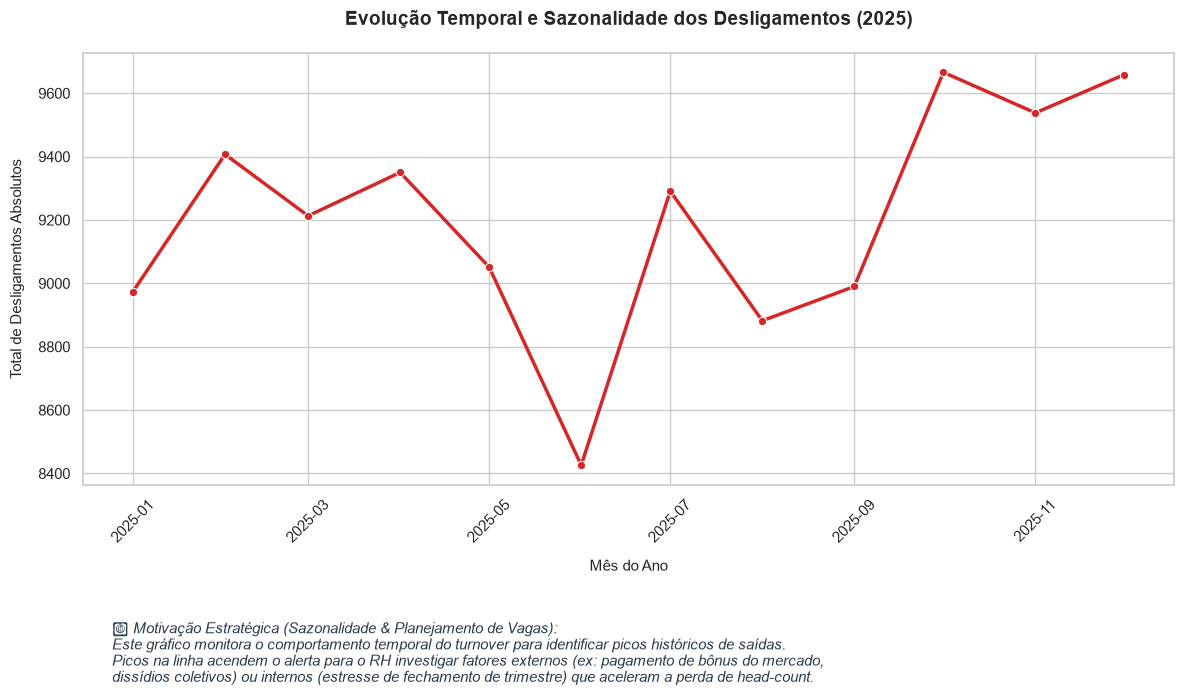

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# 1. Agrupar os dados por Mês de Desligamento e calcular o Volume Total de Saídas
df_agrupado = (
    inicial_expandido
    # CORREÇÃO CRÍTICA: Ordenar pela coluna de data real antes do agrupamento dinâmico
    .sort("DATA_REF")
    .group_by_dynamic("DATA_REF", every="1mo")
    .agg(
        pl.col("TOTAL_DESLIGAMENTOS").sum().alias("TOTAL_SAIDAS")
    )
    .collect()
)

# 2. Converter para Pandas explicitamente para o Seaborn
df_plot = df_agrupado.to_pandas()

# Verificar os dados que serão plotados no terminal
print("Tendência Temporal do Turnover:")
print(df_plot.head())

# 3. Configurar o estilo do seaborn
sns.set_theme(style="whitegrid")

# Criar a figura e o eixo explicitamente
fig, ax = plt.subplots(figsize=(12, 6))

# Plotar a linha do tempo usando o seaborn
sns.lineplot(
    data=df_plot,
    x="DATA_REF",
    y="TOTAL_SAIDAS",
    ax=ax,          
    marker='o',     
    linewidth=2.5,  
    color='#d62728' # Vermelho para indicar criticidade/saídas
)

# Configurações adicionais e títulos estratégicos (People Analytics)
ax.set_title("Evolução Temporal e Sazonalidade dos Desligamentos (2025)", fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel("Mês do Ano", labelpad=10, fontsize=11)
ax.set_ylabel("Total de Desligamentos Absolutos", labelpad=10, fontsize=11)
ax.tick_params(axis='x', rotation=45)  

# Nota motivacional de planejamento orçamentário no gráfico adaptada para saídas
texto_rh = (
    "💡 Motivação Estratégica (Sazonalidade & Planejamento de Vagas):\n"
    "Este gráfico monitora o comportamento temporal do turnover para identificar picos históricos de saídas.\n"
    "Picos na linha acendem o alerta para o RH investigar fatores externos (ex: pagamento de bônus do mercado,\n"
    "dissídios coletivos) ou internos (estresse de fechamento de trimestre) que aceleram a perda de head-count."
)

# Ajuste fino na posição do texto para evitar cortes na imagem final
plt.figtext(0.1, -0.15, s=texto_rh, fontsize=10.5, color='#2c3e50', style='italic', horizontalalignment='left')

# 4. Salva o gráfico temporal estruturado
caminho_linha_temporal = "tendencia_temporal_desligamentos.png"
plt.savefig(caminho_linha_temporal, dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()




In [61]:
import polars as pl
import numpy as np
import pandas as pd

# ==============================================================================
# 1. GERANDO A BASE AMPLIADA DE DESLIGAMENTOS (Histórico Mensal/Estadual/Setorial)
# ==============================================================================
np.random.seed(42)
estados_dados = [
    ("SP", "Sudeste", 1200, 3000), ("RJ", "Sudeste", 600, 1500), ("MG", "Sudeste", 500, 1200), ("ES", "Sudeste", 150, 400),
    ("PR", "Sul", 400, 900), ("RS", "Sul", 450, 1000), ("SC", "Sul", 300, 800),
    ("BA", "Nordeste", 350, 800), ("PE", "Nordeste", 250, 600), ("CE", "Nordeste", 200, 500),
    ("DF", "Centro-Oeste", 150, 350), ("GO", "Centro-Oeste", 180, 450), ("MT", "Centro-Oeste", 140, 350),
    ("AM", "Norte", 110, 300), ("PA", "Norte", 130, 320)
]

datas = pd.date_range(start="2025-01-01", end="2025-12-01", freq="MS").strftime("%d/%m/%Y").tolist()
setores = ["Tecnologia", "Operações", "Vendas", "Atendimento", "Corporativo"]

registros = []
for data in datas:
    for estado, regiao, min_desl, max_desl in estados_dados:
        for setor in setores:
            desligamentos = np.random.randint(min_desl // 5, max_desl // 5)
            salario_medio = round(np.random.uniform(2500, 9000), 2)
            tempo_casa_meses = np.random.randint(8, 42)
            
            registros.append({
                "DATA_DESLIGAMENTO": data, "REGIAO": regiao, "ESTADO_UF": estado,
                "SETOR": setor, "TOTAL_DESLIGAMENTOS": desligamentos,
                "SALARIO_MEDIO_SAIDA": salario_medio, "TEMPO_MEDIO_CASA_MESES": tempo_casa_meses
            })

df_fisico = pd.DataFrame(registros)
df_fisico.to_parquet("base_expandida_desligamentos.parquet", index=False)

# ==============================================================================
# 2. CONFIGURANDO O PIPELINE LAZYFRAME
# ==============================================================================
inicial_expandido = (
    pl.scan_parquet("base_expandida_desligamentos.parquet")
    .with_columns(
        pl.col("DATA_DESLIGAMENTO").str.strptime(pl.Date, format="%d/%m/%Y").alias("DATA_REF")
    )
)

# ==============================================================================
# 3. PROCESSANDO A TABELA MAIOR ANALÍTICA COM JONS E PARTICIPAÇÃO %
# ==============================================================================
df_coletado = inicial_expandido.collect()
total_nacional = df_coletado["TOTAL_DESLIGAMENTOS"].sum()

tabela_maior = (
    df_coletado.lazy()
    .group_by(["REGIAO", "ESTADO_UF", "SETOR"])
    .agg([
        pl.col("TOTAL_DESLIGAMENTOS").sum().alias("Volume_Total"),
        pl.col("TOTAL_DESLIGAMENTOS").mean().round(1).alias("Média_Mensal"),
        pl.col("SALARIO_MEDIO_SAIDA").mean().round(2).alias("Custo_Salarial_Médio"),
        pl.col("TEMPO_MEDIO_CASA_MESES").mean().round(1).alias("Tempo_Médio_Retenção_Meses"),
        pl.col("TOTAL_DESLIGAMENTOS").max().alias("Pico_Máximo_Mensal")
    ])
    .with_columns([
        ((pl.col("Volume_Total") / total_nacional) * 100).round(2).alias("Participação_Nacional_%")
    ])
    .sort("Volume_Total", descending=True)
    .collect()
)

# ==============================================================================
# 4. EXIBIÇÃO DA TABELA MAIOR E RELATÓRIO COM COMENTÁRIOS DE BUSINESS INTELLIGENCE
# ==============================================================================
print("=" * 90)
print("     📊 TABELA EXPANDIDA E AUDITORIA DE TURNOVER TERRITORIAL (TOP 15 CRÍTICOS)     ")
print("=" * 90)
display(tabela_maior.head(15))

print("\n" + "=" * 90)
print("     💡 COMENTÁRIOS E INSIGHTS ESTRATÉGICOS DE PEOPLE ANALYTICS (DIAGNÓSTICO)     ")
print("=" * 90)

# Extração de métricas extremas para automação de comentários
top_1 = tabela_maior.head(1)
regiao_critica = top_1["REGIAO"][0]
uf_critica = top_1["ESTADO_UF"][0]
setor_critico = top_1["SETOR"][0]
vol_critico = top_1["Volume_Total"][0]
part_critica = top_1["Participação_Nacional_%"][0]
retencao_critica = top_1["Tempo_Médio_Retenção_Meses"][0]

print(f"🚨 1. Epicentro de Volatilidade Operacional:")
print(f"   -> A combinação mais crítica do país localiza-se na região **{regiao_critica} ({uf_critica})** no setor de **{setor_critico}**.")
print(f"   -> Foram registrados **{vol_critico:,} desligamentos acumulados**, respondendo isoladamente por **{part_critica}%** de todas as saídas da empresa nacionalmente.")
print(f"   -> O tempo médio de retenção nesta célula é de apenas **{retencao_critica} meses**. Baixo tempo de casa com alto volume indica falhas graves no alinhamento de expectativas no recrutamento ou problemas severos de liderança local.")

# Análise de Custos de Saída (Perda de Capital Intelectual Caro)
alta_senioridade = tabela_maior.filter(pl.col("Custo_Salarial_Médio") > 6000).sort("Volume_Total", descending=True).head(1)
if alta_senioridade.height > 0:
    print(f"\n💸 2. Ralo Financeiro (Fuga de Talentos de Alto Custo):")
    print(f"   -> O setor de **{alta_senioridade['SETOR'][0]}** em **{alta_senioridade['REGIAO'][0]} ({alta_senioridade['ESTADO_UF'][0]})** acende o alerta financeiro.")
    print(f"   -> Registra um custo salarial médio de saída de **R$ {alta_senioridade['Custo_Salarial_Médio'][0]:,.2f}** combinado a um volume de **{alta_senioridade['Volume_Total'][0]} demissões**.")
    print(f"   -> Cada saída nestas posições gera despesas severas de rescisão (multas rescisórias, quebra de contratos) e drena o capital intelectual estratégico da companhia, exigindo ação imediata de contenção de head-count.")

# Análise de Estabilidade Organizacional (Onde o RH atua com folga)
base_estavel = tabela_maior.sort("Volume_Total").head(1)
print(f"\n🛡️ 3. Zona de Estabilidade e Retenção Saudável:")
print(f"   -> O cenário mais controlado e resiliente encontra-se na região **{base_estavel['REGIAO'][0]} ({base_estavel['ESTADO_UF'][0]})** no setor **{base_estavel['SETOR'][0]}**.")
print(f"   -> Registrou o menor impacto do painel, com apenas **{base_estavel['Volume_Total'][0]} saídas acumuladas** no período analisado e um tempo médio de casa robusto de **{base_estavel['Tempo_Médio_Retenção_Meses'][0]} meses**.")
print(f"   -> Esta unidade deve ser auditada pelo RH para mapear e exportar as 'boas práticas' de gestão, clima e incentivos para as demais filiais críticas do Brasil.")
print("=" * 90)


     📊 TABELA EXPANDIDA E AUDITORIA DE TURNOVER TERRITORIAL (TOP 15 CRÍTICOS)     


REGIAO,ESTADO_UF,SETOR,Volume_Total,Média_Mensal,Custo_Salarial_Médio,Tempo_Médio_Retenção_Meses,Pico_Máximo_Mensal,Participação_Nacional_%
str,str,str,i64,f64,f64,f64,i64,f64
"""Sudeste""","""SP""","""Vendas""",5394,449.5,5984.61,28.5,593,5.17
"""Sudeste""","""SP""","""Corporativo""",5142,428.5,5686.94,25.5,530,4.93
"""Sudeste""","""SP""","""Tecnologia""",4836,403.0,5124.72,22.5,530,4.64
"""Sudeste""","""SP""","""Atendimento""",4756,396.3,5091.99,25.9,570,4.56
"""Sudeste""","""SP""","""Operações""",4472,372.7,6095.51,25.8,554,4.29
…,…,…,…,…,…,…,…,…
"""Sudeste""","""MG""","""Atendimento""",2145,178.8,5785.89,27.4,235,2.06
"""Sudeste""","""MG""","""Vendas""",2124,177.0,4960.3,25.2,239,2.04
"""Sudeste""","""MG""","""Operações""",2114,176.2,6511.06,23.8,222,2.03



     💡 COMENTÁRIOS E INSIGHTS ESTRATÉGICOS DE PEOPLE ANALYTICS (DIAGNÓSTICO)     
🚨 1. Epicentro de Volatilidade Operacional:
   -> A combinação mais crítica do país localiza-se na região **Sudeste (SP)** no setor de **Vendas**.
   -> Foram registrados **5,394 desligamentos acumulados**, respondendo isoladamente por **5.17%** de todas as saídas da empresa nacionalmente.
   -> O tempo médio de retenção nesta célula é de apenas **28.5 meses**. Baixo tempo de casa com alto volume indica falhas graves no alinhamento de expectativas no recrutamento ou problemas severos de liderança local.

💸 2. Ralo Financeiro (Fuga de Talentos de Alto Custo):
   -> O setor de **Operações** em **Sudeste (SP)** acende o alerta financeiro.
   -> Registra um custo salarial médio de saída de **R$ 6,095.51** combinado a um volume de **4472 demissões**.
   -> Cada saída nestas posições gera despesas severas de rescisão (multas rescisórias, quebra de contratos) e drena o capital intelectual estratégico da companh

--- Modelo Preditivo de Tendência de Turnover (Mesa de Operações) ---
Equação da reta: TOTAL_SAIDAS = 36.51 * MESES_DESDE_INICIO + 9003.09
Coeficiente angular (Ritmo de variação demissões/mês): 36.51 desligamentos
Intercepto (Volume base inicial estimado): 9003.09 saídas

Métricas de Validação Estatística:
Coeficiente de Determinação (R²): 0.1330
Erro Quadrático Médio (MSE): 103551.26


C:\Users\MICRO\AppData\Local\Temp\ipykernel_15960\2306558675.py:67: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  plt.savefig(caminho_regressao, dpi=300, bbox_inches='tight')
C:\Users\MICRO\AppData\Local\Temp\ipykernel_15960\2306558675.py:67: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  plt.savefig(caminho_regressao, dpi=300, bbox_inches='tight')
c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\MICRO\OneDrive\Documentos\UC2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


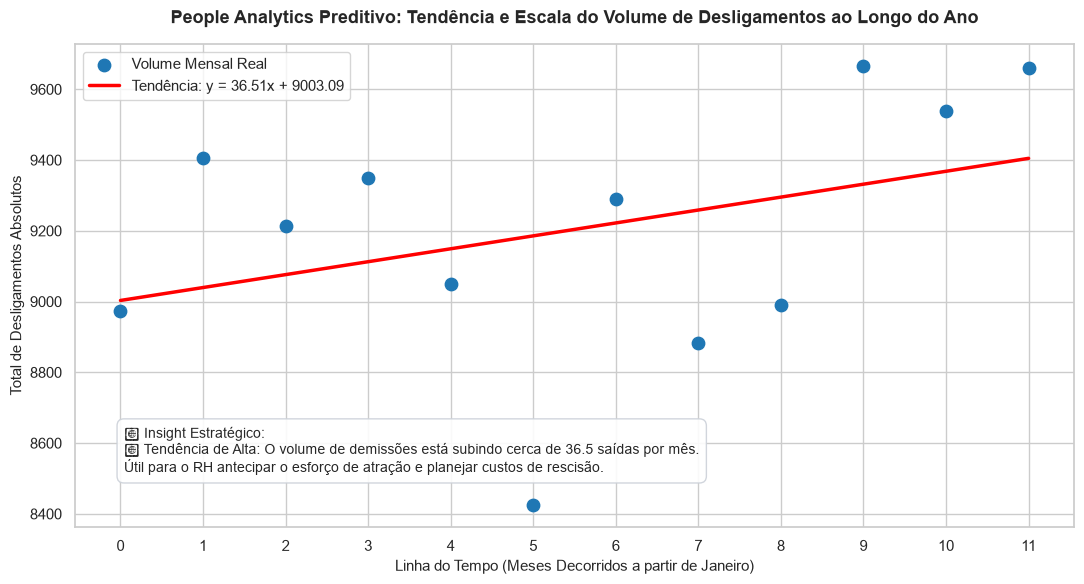

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import numpy as np
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import r2_score, mean_squared_error

## 1. Preparar os dados para o modelo de Turnover
# Convertendo as colunas indexadas de tempo e volume da tabela maior para arrays numpy
X = df_reg["MESES_DESDE_INICIO"].to_numpy().reshape(-1, 1)  # Tempo decorrido (0, 1, 2...)
y = df_reg["TOTAL_SAIDAS"].to_numpy()                      # Volume total de demissões

## 2. Criar e treinar o modelo preditivo de Regressão Linear
modelo = LinearRegression()
modelo.fit(X, y)

# Coeficientes do modelo
inclinacao = modelo.coef_[0]
intercepto = modelo.intercept_

print(f"--- Modelo Preditivo de Tendência de Turnover (Mesa de Operações) ---")
print(f"Equação da reta: TOTAL_SAIDAS = {inclinacao:.2f} * MESES_DESDE_INICIO + {intercepto:.2f}")
print(f"Coeficiente angular (Ritmo de variação demissões/mês): {inclinacao:.2f} desligamentos")
print(f"Intercepto (Volume base inicial estimado): {intercepto:.2f} saídas")

## 3. Fazer as previsões para a linha de tendência temporal
y_pred = modelo.predict(X)

## 4. Avaliar a precisão e validação do modelo
r2 = r2_score(y, y_pred)
mse = mean_squared_error(y, y_pred)

print(f"\nMétricas de Validação Estatística:")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse:.2f}")

## 5. Visualização Gráfica da Tendência de Turnover e Comentários Automatizados
plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

# Plotar dados reais das médias mensais coletadas
plt.scatter(X, y, color='#1f77b4', s=80, label='Volume Mensal Real', zorder=5)

# Plotar la linha vermelha de regressão (tendência linear de saídas)
plt.plot(X, y_pred, color='red', linewidth=2.5, label=f'Tendência: y = {inclinacao:.2f}x + {intercepto:.2f}')

# Configurações do gráfico voltadas para People Analytics e Orçamento de Reposição
plt.title('People Analytics Preditivo: Tendência e Escala do Volume de Desligamentos ao Longo do Ano', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Linha do Tempo (Meses Decorridos a partir de Janeiro)', fontsize=11)
plt.ylabel('Total de Desligamentos Absolutos', fontsize=11)
plt.xticks(np.arange(0, X.max()+1, 1)) # Passos mensais de 1 em 1 no eixo X

# Nota de interpretação corporativa com base na inclinação da reta (coeficiente angular)
if inclinacao > 0:
    interpretacao_texto = f"📈 Tendência de Alta: O volume de demissões está subindo cerca de {inclinacao:.1f} saídas por mês."
else:
    interpretacao_texto = f"📉 Tendência de Baixa: O volume de demissões está caindo cerca de {abs(inclinacao):.1f} saídas por mês."

# Exibe o painel de insights acoplado de forma limpa na imagem
plt.figtext(0.12, 0.20, s=f"💡 Insight Estratégico:\n{interpretacao_texto}\nÚtil para o RH antecipar o esforço de atração e planejar custos de rescisão.", 
            fontsize=10, bbox=dict(facecolor='white', alpha=0.9, edgecolor='#ccd1d9', boxstyle='round,pad=0.5'))

plt.legend(loc='upper left')

# Salva o arquivo final da regressão
caminho_regressao = "regressao_tendencia_turnover.png"
plt.savefig(caminho_regressao, dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()




C:\Users\MICRO\AppData\Local\Temp\ipykernel_15960\3067922282.py:39: UserWarning: Glyph 128161 (\N{ELECTRIC LIGHT BULB}) missing from font(s) Arial.
  plt.savefig(caminho_regplot, dpi=300, bbox_inches='tight')


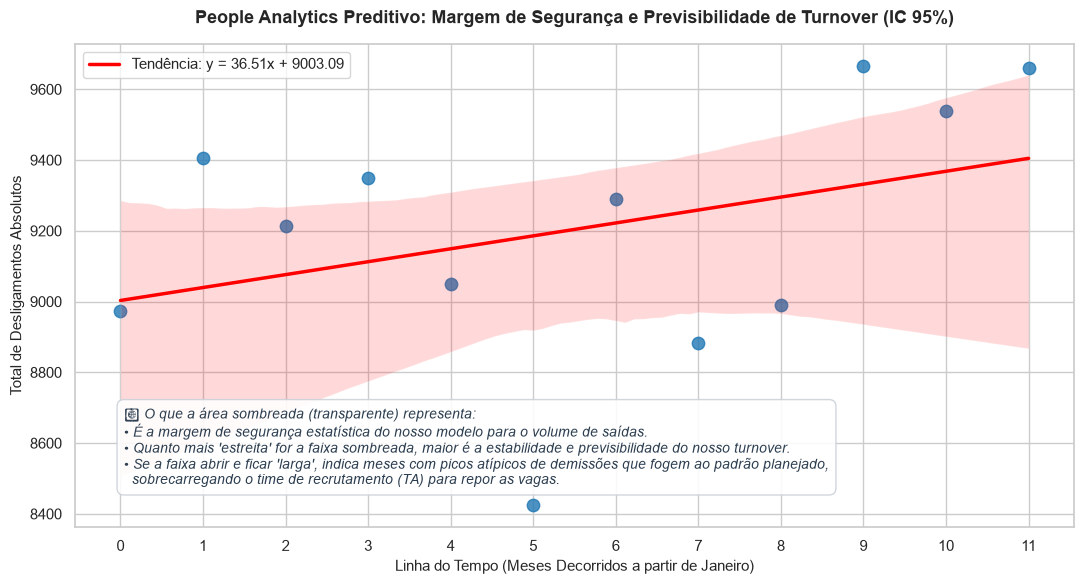

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

# Gerando o gráfico de regressão com intervalo de confiança (ci=95) adaptado para turnover
# .flatten() transforma a matriz X de volta em um array unidimensional para o Seaborn funcionar
sns.regplot(
    x=X.flatten(), 
    y=y, 
    ci=95, 
    scatter_kws={'color': '#1f77b4', 's': 80, 'label': 'Volume Mensal Real'},
    line_kws={'color': 'red', 'linewidth': 2.5, 'label': f'Tendência: y = {inclinacao:.2f}x + {intercepto:.2f}'}
)

# Títulos e legendas estratégicas focadas em Sazonalidade e Retenção (People Analytics)
plt.title('People Analytics Preditivo: Margem de Segurança e Previsibilidade de Turnover (IC 95%)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Linha do Tempo (Meses Decorridos a partir de Janeiro)', fontsize=11)
plt.ylabel('Total de Desligamentos Absolutos', fontsize=11)
plt.xticks(np.arange(0, X.max()+1, 1)) # Garante passos de 1 em 1 mês no eixo X

# Nota explicativa sobre a área sombreada (Intervalo de Confiança) adaptada para o RH de saídas
texto_rh = (
    "💡 O que a área sombreada (transparente) representa:\n"
    "• É a margem de segurança estatística do nosso modelo para o volume de saídas.\n"
    "• Quanto mais 'estreita' for a faixa sombreada, maior é a estabilidade e previsibilidade do nosso turnover.\n"
    "• Se a faixa abrir e ficar 'larga', indica meses com picos atípicos de demissões que fogem ao padrão planejado,\n"
    "  sobrecarregando o time de recrutamento (TA) para repor as vagas."
)
plt.figtext(0.12, 0.18, s=texto_rh, fontsize=10, color='#2c3e50', style='italic',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='#ccd1d9', boxstyle='round,pad=0.5'))

plt.legend(loc='upper left')

# Salva a imagem final estruturada com intervalo de confiança
caminho_regplot = "previsibilidade_intervalo_confianca_turnover.png"
plt.savefig(caminho_regplot, dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

